<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:43: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\l'
<>:42: SyntaxWarning: invalid escape sequence '\l'
<>:43: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:47: SyntaxWarning: invalid escape sequence '\l'
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_71819/1022459714.py:42: SyntaxWarning: invalid escape sequence '\l'
  plt.axvline(lambda2, color='red', alpha=0.5, label='$\lambda_2$')
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_71819/1022459714.py:43: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(mu1, color='brown', alpha=0.5, label='$\mu_1$')
/var/folders/nz/jn74t1g51q10qyclfkkr8cgm0000gq/T/ipykernel_71819/1022459714.py:44: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(mu2, color='orange', alpha=0.5, label='$\mu_2$')
/var/folders/nz/jn

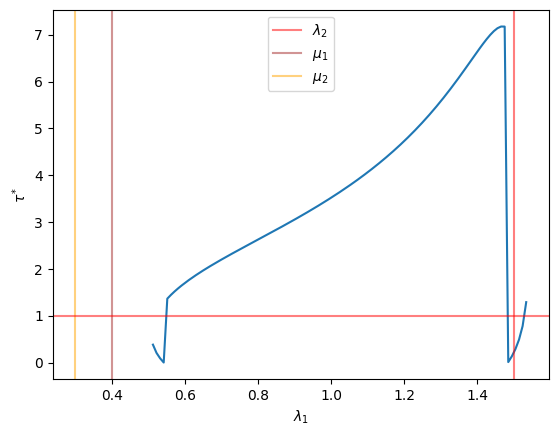

In [23]:
import numpy as np
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

lambda2 = 1.5
mu1 = 0.4
mu2 = 0.3
t = 1

def tau_star(lambda1):

    r1 = lambda1 - mu1
    r2 = lambda2 - mu2

    C = np.exp(r2*t) * ((r2 - r1)*r1*lambda2/(r1 + r2))

    def f(tau):
        return ((mu1*lambda2 - mu2*lambda1)*np.exp(-r2*tau)
                + mu1*mu2*np.exp((r2-r1)*tau)
                - C)

    grid = np.linspace(0,10,500)

    vals = f(grid)

    sign_change = np.where(np.diff(np.sign(vals)))[0]

    if len(sign_change) == 0:
        return np.nan

    a = grid[sign_change[0]]
    b = grid[sign_change[0] + 1]

    sol = root_scalar(f, bracket=[a,b])
    return sol.root


l1_vals = np.linspace(0.1,5,500)
taus = [tau_star(l1) for l1 in l1_vals]

plt.plot(l1_vals, taus)
plt.axvline(lambda2, color='red', alpha=0.5, label='$\lambda_2$')
plt.axvline(mu1, color='brown', alpha=0.5, label='$\mu_1$')
plt.axvline(mu2, color='orange', alpha=0.5, label='$\mu_2$')

plt.axhline(1, color='red', alpha=0.5,)
plt.xlabel("$\lambda_1$")
plt.ylabel("${\\tau}^{*}$")
plt.legend()
plt.show()